# From segmentation fidelity to tumor–immune organization: CD8 infiltration, immune exclusion, Treg regulation

One biological question, asked of every segmentation method on the test slide (Slide 2, SLIDE-0236, six reviewed regions): **do cytotoxic T cells
reach the tumor?** (The test split also holds the four fields of Slide 3, SLIDE-0233; every result table below is restricted to Slide 2's
region keys, nothing pools the two slides.) The expert's cells and every method's predicted cells pass through the *same* pipeline — the panel gates calibrated
on the biologist's labels of the development slide (`configs/panel.yaml`, notebook 00d), a Delaunay contact graph, a PanCK⁺ tumor
compartment — so every difference downstream is caused by the cell boundaries alone.

| level | endpoint | what it measures |
|---|---|---|
| primary | **tumor–CD8 interaction fidelity** | the expert's PanCK⁺–CD8⁺ contacts a method recovers (recall / precision / F1 of contacts, and the CD8 infiltration score) |
| contrast | **immune exclusion fidelity** | whether T cells sit inside, at the margin of, or away from the tumor compartment — infiltrated vs excluded — and whether the method calls the region the same way |
| secondary | **Treg spatial fidelity** | FOXP3⁺ T cells next to tumor and next to CD8 cells: the regulated vs unopposed CD8 ecosystem |
| link | PQ vs biological fidelity | segmentation quality (Panoptic Quality) against the endpoints, one point per method × region |
| claim | tumor–immune **interface error rate** | E = incorrectly segmented tumor–immune contacts / expert tumor–immune contacts: does it predict fidelity better than PQ? |

Phenotype classes used here (from the panel hierarchy): **Tumor** = PanCK⁺; **CD8 T** = CD3⁺CD8⁺; **Treg** = CD3⁺FOXP3⁺;
CD4 T = CD3⁺CD4⁺; T other = CD3⁺ only; Other. **No classifier is involved**: a cell's class comes from its marker means against the
panel's thresholds (each the maximum-F1 threshold on the biologist's labels, `scripts/calibrate_gates.py`), and a region's call from a
fixed rule on its endpoints. Figures are written as vector PDFs to `outputs/figures/analyses/`. Contacts are Delaunay neighbors within `CONTACT_UM`; the tumor compartment is the union
of tumor cells closed over `COMPARTMENT_UM`; a T cell is *intratumoral* inside it, *marginal* within `MARGIN_UM` of it, *distant* beyond.

In [1]:
%load_ext autoreload
%autoreload 2
import json, re, itertools, warnings
from pathlib import Path
from scipy.stats import ConstantInputWarning
warnings.filterwarnings("ignore", category=ConstantInputWarning)
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi
from scipy.spatial import Delaunay, cKDTree
from scipy.stats import spearmanr

from mxdata import DEFAULT_DATASET, apply_qc_policy, ingest, load_config, load_regions
from mxdata.data import LiveSource
from mxdata.data.composite import render_channels
from mxdata.pipeline.stats import NormStats
from mxseg.analysis import assign_phenotypes, load_panel, phenotype_gates
from mxseg.metrics import instance_outcomes

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
RESULTS, PRED, OUT = REPO / "results" / "region" / "test", REPO / "outputs" / "region" / "test", REPO / "outputs" / "analysis"
DATASET = Path(DEFAULT_DATASET)

# ---- edit here ---------------------------------------------------------------------------------------------------------
SLIDE = "SLIDE-0236"                    # the test slide
CONTACT_UM = 15.0                       # Delaunay neighbors closer than this are in contact (two cell diameters)
COMPARTMENT_UM = 4.0                    # closing radius that turns tumor cells into a tumor compartment
MARGIN_UM = 20.0                        # a T cell within this distance of the compartment is marginal; beyond, distant
TREG_UM = 20.0                          # a CD8 cell with a Treg within this distance is "regulated"
SHOW = ["unet_flows", "kodiakb_flows", "cellpose_ft"]        # the ROI figure (seed 0): the U-Net baseline, the foundation model (ViT-B/16) matched to it on PQ, Cellpose adapted
# FIG_REGION is chosen by a rule stated in the caption, not by eye: among regions with |PQ(kodiakb_flows) - PQ(unet_flows)| < 0.02
# and at least 8 expert tumor-CD8 contacts (seed 0), the one maximizing |contact F1 difference| -- R01 (dPQ +0.001, dF1 +0.18, 18 contacts);
# cell 6 evaluates the rule and prints it.
FIG_REGION = "SLIDE-0236_R01"           # the ROI figure: the one CD8-infiltrated region, 18 of the slide's 40 tumor-CD8 contacts; None = most contacts
# ------------------------------------------------------------------------------------------------------------------------

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
OURS = "KODIAK"                          # camera-ready: the real name
LABEL = {"unet_flows": "U-Net", "kodiakb_flows": f"{OURS} B/16", "dinov3b_flows": "DINOv3 B/16", "kodiakb_frozen": f"{OURS} B/16, frozen",
         "dinov3b_frozen": "DINOv3 B/16, frozen", "cellpose_ft": "Cellpose, adapted", "cellpose": "Cellpose-SAM, zero-shot",
         "cpdino": "Cellpose (DINOv3), zero-shot", "instanseg": "InstanSeg", "sam3": "SAM 3", "sam3_text": "SAM 3, text", "sam2": "SAM 2.1"}
MCOLOR = {"unet_flows": "#2A78D6", "kodiakb_flows": "#7E1F2E", "dinov3b_flows": "#6E5314", "kodiakb_frozen": "#DF959E", "dinov3b_frozen": "#D3BF8C",
          "cellpose_ft": "#EB6834", "cellpose": "#8A8A8A", "cpdino": "#5A5A5A", "instanseg": "#3C9D9B", "sam3": "#1BAF7A", "sam3_text": "#E87BA4", "sam2": "#9A86E0"}
# the trained rows (ViT-B only, 10-epoch budget, 3 seeds each) first, then the zero-shot rows
ORDER = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "cellpose_ft", "kodiakb_frozen", "dinov3b_frozen", "cellpose", "cpdino", "instanseg", "sam3", "sam3_text", "sam2"]
# The three markers that carry the story (PanCK, CD8, FOXP3) are the only saturated colors; everything else recedes.
CLASS = {"Tumor": "#3FA96B", "CD8 T": "#5B2BD9", "Treg": "#E11D74", "CD4 T": "#C9A227", "T other": "#E08A3C", "Other immune": "#E0B4B4", "Other": "#E7EAEF"}
FILL = {"Tumor": "#DCF0E4", "Other": "#F1F3F6"}                  # the contact row: a map under the graph
CONTACT = {"recovered": "#14181D", "lost": "#E5484D", "new": "#2A78D6"}
ZONE = {"intratumoral": "#5B2BD9", "marginal": "#E08A3C", "distant": "#9AA3AD"}
COMP_FILL, COMP_MARGIN, COMP_EDGE, EDGE_ALL = "#C9E7D6", "#EFF4F1", "#3FA96B", "#CBD1D9"
ROI_PANEL = 1.30                        # the paper's ROI panels are drawn at this size in inches and never rescaled by LaTeX
ROI_CROP = 448                          # the zoom, in pixels: tight enough that a 15 um contact reads at 1.30 in (cell 9 prints the options)
FIGDIR = REPO / "outputs" / "figures" / "analyses"; FIGDIR.mkdir(parents=True, exist_ok=True)
PAPERFIG = REPO / "LaTex" / "figures" / "spatial"; PAPERFIG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    """The analysis copy: the whole figure, for reading the notebook."""
    fig.savefig(FIGDIR / f"10_{name}.pdf", bbox_inches="tight"); fig.savefig(FIGDIR / f"10_{name}.png", dpi=250, bbox_inches="tight")

def save_panels(fig, stem, axes, letters=None, extras=None):
    """ONE PDF PER PANEL in LaTex/figures/spatial/<stem>_<letter>.pdf, cut out of a wide figure on each axes' own
    ``get_tightbbox`` intersected with the half-way line to its neighbours. Only the ROI figure below still uses this.
    The paper's Figures 5 and 6 are NOT cut out of these notebook figures any more: a panel drawn 3.3 in wide and then
    shrunk into a 1.3 in column is what made them illegible. ``scripts/figure_spatial.py`` redraws them at their final
    print size from ``tumor_immune_fidelity.csv`` and ``tumor_immune_expert_regions.csv``, written below."""
    from matplotlib.transforms import Bbox
    r = fig.canvas.get_renderer()
    letters = letters or [chr(ord("a") + i) for i in range(len(axes))]
    xs = sorted(a.get_position().x0 for a in axes)
    for k, (ax, letter) in enumerate(zip(axes, letters)):
        bb = ax.get_tightbbox(r)
        for e in (extras or {}).get(letter, []):
            bb = Bbox.union([bb, e.get_window_extent()])
        lo = 0 if k == 0 else (xs[k - 1] + xs[k]) / 2 * fig.bbox.width
        hi = fig.bbox.width if k == len(axes) - 1 else (xs[k] + xs[k + 1]) / 2 * fig.bbox.width
        bb = Bbox([[max(bb.x0, lo), bb.y0], [min(bb.x1, hi), bb.y1]])
        fig.savefig(PAPERFIG / f"{stem}_{letter}.pdf", bbox_inches=bb.transformed(fig.dpi_scale_trans.inverted()), pad_inches=0.03)

def hexrgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)], np.float32)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def scalebar(ax, npx_w, npx_h, um, color=INK, size=7):
    L = um / PX_UM; x1, y = npx_w * 0.96, npx_h * 0.94
    ax.plot([x1 - L, x1], [y, y], color=color, lw=1.8, solid_capstyle="butt")
    ax.text(x1 - L / 2, y - npx_h * 0.02, f"{um:g} \u00b5m", color=color, ha="center", va="bottom", fontsize=size, fontweight="bold")

def panel_letter(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)
def chip(ax, text):
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6))
def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)
def lab(m):
    return LABEL.get(m, m)

cfg = load_config(REPO / "configs" / "dataset.yaml"); MARKERS = list(cfg.markers)
panel = load_panel(REPO / "configs" / "panel.yaml")
st = NormStats.load(DATASET / SLIDE / "stats.json"); NORMS = {m: (float(st.lo[m]), float(st.hi[m])) for m in MARKERS}
THR = phenotype_gates(pd.DataFrame(), panel, NORMS)                 # raw-count thresholds of this slide from the calibrated normalized gates
paths, mx, _ = ingest(SLIDE, None); PX_UM = float(mx.pixel_size_um or 0.325)
regions = {r.key: r for r in load_regions(paths, None, cfg.min_area_px)}; KEYS = sorted(regions)
src = LiveSource(mx, list(regions.values()), MARKERS, cfg.level)
GT = {}
for k in KEYS:
    rs = src.load(k); labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong"); GT[k] = (rs.image, labels, ignore)
SEED_RE = re.compile(r"^(.*)_s(\d+)$")
runs = []
for m in sorted(RESULTS.glob("*/metrics.json")):
    name = m.parent.name; mm = SEED_RE.match(name); method, seed = (mm.group(1), int(mm.group(2))) if mm else (name, None)
    per = pd.read_csv(m.parent / "per_region.csv")
    per = per[per.key.str.startswith(SLIDE + "_")]                     # the test split holds two slides; this notebook is SLIDE-0236 only
    runs.append({"run": name, "method": method, "seed": seed, "per_region": per})
METHODS = [m for m in ORDER if any(r["method"] == m for r in runs)]
BY = {m: sorted([r for r in runs if r["method"] == m], key=lambda r: (r["seed"] is None, r["seed"])) for m in METHODS}
PANEL_TO_CLASS = {"Epithelial": "Tumor", "uPAR+ epithelial": "Tumor", "CD8+ T cell": "CD8 T", "Treg": "Treg", "CD4+ T cell": "CD4 T", "T cell": "T other", "Immune": "Other immune", "Other": "Other"}
assert all(set(KEYS) <= set(r["per_region"].key) for r in runs), "a run lacks a region of this slide in per_region.csv"
print(f"{len(runs)} runs of {len(METHODS)} methods on the {len(KEYS)} test regions of {SLIDE}; gates (raw counts): " + ", ".join(f"{m} {v:.0f}" for m, v in THR.items()))

24 runs of 12 methods on the 6 test regions of SLIDE-0236; gates (raw counts): PanCK 385, uPAR 2244, CD3 1502, FOXP3 749, CD8 558, CD4 4018, CD45 621


## 1. The same pipeline for every cell set

A *cell set* is a label map plus the confirmed / scored ids: for the expert, HALO's confirmed cells (flagged cells removed); for a
method, its scored predictions (those not lying on a flagged cell). Each set gets marker means → phenotype → class, a contact graph,
and a tumor compartment with distances. Nothing else differs between expert and method.

In [2]:
def cell_table(labels, image, ids):
    """One row per cell: centroid, area, raw marker means, panel phenotype, class."""
    ids = np.asarray(ids)
    t = pd.DataFrame({"id": ids})
    cen = np.array(ndi.center_of_mass(labels > 0, labels, ids)) if len(ids) else np.zeros((0, 2))
    t["cy"], t["cx"] = cen[:, 0], cen[:, 1]; t["area"] = np.bincount(labels.ravel(), minlength=labels.max() + 1)[ids]
    for m in panel.gate_markers:
        t[m] = ndi.mean(image[MARKERS.index(m)].astype(np.float32), labels, ids)
    ph, lin = assign_phenotypes(t, panel, THR); t["phenotype"] = ph.values; t["cls"] = ph.map(PANEL_TO_CLASS).values
    return t.set_index("id")

def contact_graph(t):
    """Delaunay neighbors closer than CONTACT_UM, as a set of (id, id) with id < id."""
    if len(t) < 4:
        return set()
    pts = t[["cx", "cy"]].values; tri = Delaunay(pts); ids = t.index.values
    e = set()
    for s in tri.simplices:
        for a, b in itertools.combinations(s, 2):
            if np.hypot(*(pts[a] - pts[b])) * PX_UM <= CONTACT_UM:
                e.add((int(min(ids[a], ids[b])), int(max(ids[a], ids[b]))))
    return e

def compartment(labels, t):
    """The tumor compartment: tumor cells closed with a COMPARTMENT_UM disk, holes filled; and each cell's distance (µm) to it."""
    tumor = np.isin(labels, t.index[t.cls == "Tumor"].values)
    r = int(round(COMPARTMENT_UM / PX_UM)); k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
    comp = cv2.morphologyEx(tumor.astype(np.uint8), cv2.MORPH_CLOSE, k).astype(bool); comp = ndi.binary_fill_holes(comp)
    dist = ndi.distance_transform_edt(~comp) * PX_UM if comp.any() else np.full(labels.shape, np.inf)
    d = dist[np.round(t.cy.values).astype(int).clip(0, labels.shape[0] - 1), np.round(t.cx.values).astype(int).clip(0, labels.shape[1] - 1)]
    zone = np.where(d <= 0, "intratumoral", np.where(d <= MARGIN_UM, "marginal", "distant"))
    return comp, pd.Series(d, index=t.index), pd.Series(zone, index=t.index)

def analyse(labels, image, ids):
    """Everything downstream for one cell set: table, contacts, compartment, endpoints."""
    t = cell_table(labels, image, ids); E = contact_graph(t); comp, dist, zone = compartment(labels, t)
    t["dist_um"], t["zone"] = dist, zone
    cls = t.cls
    tc = {(a, b) for a, b in E if {cls[a], cls[b]} == {"Tumor", "CD8 T"}}                     # tumor-CD8 contacts
    ttreg = {(a, b) for a, b in E if {cls[a], cls[b]} == {"Tumor", "Treg"}}
    tT = {(a, b) for a, b in E if "Tumor" in {cls[a], cls[b]} and ({cls[a], cls[b]} & {"CD8 T", "Treg", "CD4 T", "T other"})}   # any tumor-T contact
    cd8 = t.index[cls == "CD8 T"].values; treg = t.index[cls == "Treg"].values; tcells = t.index[cls.isin(["CD8 T", "Treg", "CD4 T", "T other"])].values
    touching = {i for e in tc for i in e if cls[i] == "CD8 T"}
    t["cd8_touching"] = t.index.isin(list(touching))
    reg = set()
    if len(treg) and len(cd8):
        tree = cKDTree(t.loc[treg, ["cx", "cy"]].values); d, _ = tree.query(t.loc[cd8, ["cx", "cy"]].values); reg = set(cd8[d * PX_UM <= TREG_UM])
    t["cd8_regulated"] = t.index.isin(list(reg))
    ep = {"n_tumor": int((cls == "Tumor").sum()), "n_cd8": len(cd8), "n_treg": len(treg), "n_T": len(tcells),
          "tumor_cd8_contacts": len(tc), "tumor_treg_contacts": len(ttreg), "tumor_T_contacts": len(tT),
          "cd8_touching_frac": len(touching) / max(len(cd8), 1), "cd8_intratumoral_frac": float((zone[cd8] == "intratumoral").mean()) if len(cd8) else np.nan,
          "cd8_distant_frac": float((zone[cd8] == "distant").mean()) if len(cd8) else np.nan, "T_distant_frac": float((zone[tcells] == "distant").mean()) if len(tcells) else np.nan,
          "cd8_median_dist_um": float(np.median(dist[cd8])) if len(cd8) else np.nan, "cd8_regulated_frac": len(reg) / max(len(cd8), 1),
          "treg_near_tumor_frac": float((dist[treg] <= MARGIN_UM).mean()) if len(treg) else np.nan}
    return {"t": t, "E": E, "tc": tc, "ttreg": ttreg, "tT": tT, "comp": comp, "ep": ep}

def region_call(ep, min_cells=5):
    """The biologist's three-way reading of a region from its endpoints, one rule for expert and methods."""
    if ep["n_cd8"] < min_cells and ep["n_T"] < min_cells:
        return "sparse"
    infiltrated = ep["cd8_touching_frac"] >= 0.3 or ep["cd8_intratumoral_frac"] >= 0.3
    if not infiltrated:
        return "immune-excluded"
    return "CD8-infiltrated, Treg-regulated" if ep["cd8_regulated_frac"] >= 0.3 else "CD8-infiltrated"

# ---- the expert reference and every run, on every region --------------------------------------------------------------
REF, RUN = {}, {}
for k in KEYS:
    image, labels, ignore = GT[k]
    o0 = instance_outcomes(labels, labels, ignore=ignore, thr=0.5)                          # the expert against itself: confirmed ids and the relabeled map
    ids = np.nonzero(np.isin(o0["gt_status"][1:], ["tp", "fn"]))[0] + 1
    REF[k] = analyse(o0["gt"], image, ids); REF[k]["gt_map"] = o0["gt"]
for r in runs:
    for k in KEYS:
        f = PRED / r["run"] / f"{k}.npz"
        if not f.is_file():
            continue
        image, labels, ignore = GT[k]
        o = instance_outcomes(labels, np.load(f)["pred"].astype(np.int32), ignore=ignore, thr=0.5)
        pids = np.nonzero(np.isin(o["pred_status"][1:], ["tp", "fp"]))[0] + 1
        a = analyse(o["pred"], image, pids); a["pairs"] = {int(g) + 1: int(p) + 1 for g, p in o["pairs"]}; a["gt_status"] = o["gt_status"]
        G, P = int(o["gt"].max()), int(o["pred"].max())
        inter = np.bincount((o["gt"].astype(np.int64) * (P + 1) + o["pred"]).ravel(), minlength=(G + 1) * (P + 1)).reshape(G + 1, P + 1)[1:, 1:]
        cover_g = inter / np.maximum(inter.sum(1, keepdims=True), 1)                        # fraction of each expert cell inside each prediction
        scored_g = np.isin(o["gt_status"][1:], ["tp", "fn"])
        a["merges"] = [list(np.nonzero((cover_g[:, p_] >= 0.5) & scored_g)[0] + 1) for p_ in range(P) if ((cover_g[:, p_] >= 0.5) & scored_g).sum() >= 2]
        RUN[(r["run"], k)] = a
EXPERT_EP = pd.DataFrame({k: REF[k]["ep"] for k in KEYS}).T.assign(call=[region_call(REF[k]["ep"]) for k in KEYS])
EXPERT_EP.to_csv(OUT / "tumor_immune_expert_regions.csv")     # the expert reference of every region; scripts/figure_spatial.py reads it with the fidelity table
print("expert endpoints per region:"); EXPERT_EP.round(2)

expert endpoints per region:


,n_tumor,n_cd8,n_treg,n_T,tumor_cd8_contacts,tumor_treg_contacts,tumor_T_contacts,cd8_touching_frac,cd8_intratumoral_frac,cd8_distant_frac,T_distant_frac,cd8_median_dist_um,cd8_regulated_frac,treg_near_tumor_frac,call
SLIDE-0236_R01,318.0,7.0,3.0,13.0,18.0,1.0,19.0,1.00,0.14,0.00,0.23,2.48,0.00,1.00,CD8-infiltrated
SLIDE-0236_R02,78.0,5.0,16.0,32.0,0.0,1.0,3.0,0.00,0.00,1.00,0.88,77.40,0.00,0.12,immune-excluded
SLIDE-0236_R03,221.0,21.0,16.0,73.0,9.0,3.0,12.0,0.14,0.14,0.81,0.82,48.57,0.24,0.25,immune-excluded
SLIDE-0236_R04,756.0,8.0,8.0,31.0,4.0,0.0,14.0,0.12,0.00,0.50,0.48,24.95,0.12,0.38,immune-excluded
SLIDE-0236_R05,345.0,16.0,18.0,76.0,7.0,4.0,11.0,0.19,0.00,0.69,0.82,45.79,0.38,0.17,immune-excluded
SLIDE-0236_R06,98.0,4.0,11.0,29.0,2.0,0.0,6.0,0.25,0.00,0.50,0.76,44.23,0.00,0.00,immune-excluded


**Table 1 — the expert's reading of the six test regions.** Tumor cells, CD8 T cells and Tregs, the tumor–CD8 contacts, the share of
CD8 cells touching tumor or inside the compartment, the share distant from it, the share with a Treg within 20 µm, and the resulting
call (rule: at least 5 CD8 or T cells, else *sparse*; ≥ 30 % of CD8 cells touching or inside tumor = *infiltrated*, else *excluded*;
infiltrated with ≥ 30 % of CD8 cells within 20 µm of a Treg = *Treg-regulated*). This is the biology every method has to reproduce.

## 2. Fidelity of every method, region by region

In [3]:
def fidelity(ref, run):
    """Endpoint fidelity of one run on one region against the expert: contacts (matched cells, same classes, still in contact), scores, calls, interface errors."""
    pairs = run["pairs"]; rt, pt = ref["t"], run["t"]; rE = run["E"]
    def recovered(edges, cls_pair):
        rec = 0
        for a, b in edges:
            pa, pb = pairs.get(a), pairs.get(b)
            if pa is None or pb is None or pa == pb or pa not in pt.index or pb not in pt.index:
                continue
            if {pt.cls[pa], pt.cls[pb]} == cls_pair and (min(pa, pb), max(pa, pb)) in rE:
                rec += 1
        return rec
    out = {}
    n_tc, rec_tc = len(ref["tc"]), recovered(ref["tc"], {"Tumor", "CD8 T"})
    inv = {v: k for k, v in pairs.items()}; rtc = ref["tc"]
    prec_hits = sum(1 for a, b in run["tc"] if inv.get(a) is not None and inv.get(b) is not None and (min(inv[a], inv[b]), max(inv[a], inv[b])) in rtc)
    out["contact_recall"] = rec_tc / n_tc if n_tc else np.nan; out["contact_precision"] = prec_hits / len(run["tc"]) if run["tc"] else np.nan
    out["contact_f1"] = 2 * rec_tc / (n_tc + len(run["tc"])) if (n_tc + len(run["tc"])) else np.nan
    out["treg_contact_recall"] = recovered(ref["ttreg"], {"Tumor", "Treg"}) / len(ref["ttreg"]) if ref["ttreg"] else np.nan
    for key in ("cd8_touching_frac", "cd8_distant_frac", "cd8_intratumoral_frac", "cd8_regulated_frac", "treg_near_tumor_frac", "T_distant_frac"):
        out[key + "_err"] = run["ep"][key] - ref["ep"][key]
    out["n_cd8_ratio"] = run["ep"]["n_cd8"] / max(ref["ep"]["n_cd8"], 1); out["n_tumor_ratio"] = run["ep"]["n_tumor"] / max(ref["ep"]["n_tumor"], 1)
    # per-cell agreement among matched CD8 cells: touching yes/no, zone
    m = [(g, pairs[g]) for g in rt.index[rt.cls == "CD8 T"] if g in pairs and pairs[g] in pt.index]
    out["cd8_matched_frac"] = len(m) / max((rt.cls == "CD8 T").sum(), 1)
    # why an expert tumor-CD8 contact is lost: a cell missed/merged/split (no correct match), a matched cell that changed class, or adjacency lost
    why = {"recovered": 0, "cell not matched": 0, "class changed": 0, "adjacency lost": 0}
    for a_, b_ in ref["tc"]:
        pa, pb = pairs.get(a_), pairs.get(b_)
        if pa is None or pb is None or pa == pb or pa not in pt.index or pb not in pt.index: why["cell not matched"] += 1
        elif {pt.cls[pa], pt.cls[pb]} != {"Tumor", "CD8 T"}: why["class changed"] += 1
        elif (min(pa, pb), max(pa, pb)) not in rE: why["adjacency lost"] += 1
        else: why["recovered"] += 1
    for k_, v_ in why.items(): out["why_" + k_.replace(" ", "_")] = v_
    out["n_expert_contacts"] = len(ref["tc"])
    out["n_run_contacts"], out["n_rec_contacts"], out["n_prec_hits"] = len(run["tc"]), rec_tc, prec_hits   # for pooling
    out["cd8_class_kept"] = np.mean([pt.cls[p] == "CD8 T" for g, p in m]) if m else np.nan
    out["cd8_touch_agree"] = np.mean([rt.cd8_touching[g] == pt.cd8_touching[p] for g, p in m]) if m else np.nan
    out["cd8_zone_agree"] = np.mean([rt.zone[g] == pt.zone[p] for g, p in m]) if m else np.nan
    out["call_expert"], out["call_run"] = region_call(ref["ep"]), region_call(run["ep"]); out["call_agree"] = out["call_expert"] == out["call_run"]
    # interface error rates: an expert contact is incorrectly segmented when either cell is not a correct match
    st = run["gt_status"]
    def err_rate(edges):
        return np.mean([not (st[a] == "tp" and st[b] == "tp") for a, b in edges]) if edges else np.nan
    homo = {(a, b) for a, b in ref["E"] if rt.cls[a] == "Tumor" and rt.cls[b] == "Tumor"}
    other = ref["tT"] - ref["tc"]                                                          # tumor contacts with CD4 T, Treg, other T: not the endpoint's own cells
    out["E_interface"] = err_rate(ref["tT"]); out["E_interface_cd8"] = err_rate(ref["tc"]); out["E_interface_other"] = err_rate(other); out["E_homotypic"] = err_rate(homo)
    out["n_expert_interfaces"] = len(ref["tT"])
    # merge anatomy: predictions that swallow two or more expert cells (each covered >= 50 %) — what did they fuse?
    mg = run["merges"]; kinds = {"tumor–tumor": 0, "tumor–T cell": 0, "T cell–T cell": 0, "other": 0}
    for cells_ in mg:
        cl = {rt.cls.get(c, "Other") for c in cells_}; tset = {"CD8 T", "Treg", "CD4 T", "T other"}
        if "Tumor" in cl and cl & tset: kinds["tumor–T cell"] += 1
        elif cl == {"Tumor"}: kinds["tumor–tumor"] += 1
        elif cl <= tset and cl: kinds["T cell–T cell"] += 1
        else: kinds["other"] += 1
    for k_, v_ in kinds.items(): out["merge_" + k_.replace(" ", "_").replace("–", "_")] = v_
    return out

rows = []
for r in runs:
    for k in KEYS:
        if (r["run"], k) not in RUN:
            continue
        pr = r["per_region"].set_index("key").loc[k]
        pq = pr["iou_sum@0.5"] / (pr["tp@0.5"] + 0.5 * pr["fp@0.5"] + 0.5 * pr["fn@0.5"]); f1 = 2 * pr["tp@0.5"] / (2 * pr["tp@0.5"] + pr["fp@0.5"] + pr["fn@0.5"])
        rows.append({"run": r["run"], "method": r["method"], "seed": r["seed"], "region": k, "PQ": pq, "F1": f1, "Dice": pr["dice"], **fidelity(REF[k], RUN[(r["run"], k)])})
FID = pd.DataFrame(rows); assert FID.region.str.startswith(SLIDE + "_").all(); FID.to_csv(OUT / "tumor_immune_fidelity.csv", index=False)

def roi_rule(df, fm="kodiakb_flows", base="unet_flows", max_dpq=0.02, min_contacts=8):
    """The pre-specified ROI rule: regions where the foundation model and the U-Net tie on PQ (|dPQ| < 0.02) and the expert has
    at least ``min_contacts`` tumor-CD8 contacts; among them the one where the contact F1 differs most."""
    a, b = df[df.method == fm].set_index("region"), df[df.method == base].set_index("region")
    cand = pd.DataFrame({"PQ_fm": a.PQ, "PQ_unet": b.PQ, "dPQ": a.PQ - b.PQ, "F1_fm": a.contact_f1, "F1_unet": b.contact_f1,
                         "dF1": a.contact_f1 - b.contact_f1, "contacts": a.n_expert_contacts})
    ok = cand[(cand.dPQ.abs() < max_dpq) & (cand.contacts >= min_contacts)]
    return cand, (ok.dF1.abs().idxmax() if len(ok) else None)
ROI_CAND, ROI_RULE = roi_rule(FID[FID.seed == 0])
print("ROI rule (seed 0, |dPQ| < 0.02, >= 8 contacts) -> " + str(ROI_RULE) + f"; FIG_REGION = {FIG_REGION}"); print(ROI_CAND.round(3).to_string())
summ = FID.groupby("method")[["PQ", "contact_f1", "contact_recall", "contact_precision", "cd8_touching_frac_err", "cd8_distant_frac_err", "cd8_regulated_frac_err", "call_agree", "E_interface", "E_homotypic"]].mean().reindex(METHODS)
summ.index = [lab(m) for m in summ.index]; summ.round(3)

ROI rule (seed 0, |dPQ| < 0.02, >= 8 contacts) -> SLIDE-0236_R01; FIG_REGION = SLIDE-0236_R01
                PQ_fm  PQ_unet    dPQ  F1_fm  F1_unet    dF1  contacts
region                                                                
SLIDE-0236_R01  0.708    0.707  0.001  0.579    0.400  0.179        18
SLIDE-0236_R02  0.684    0.675  0.009    NaN      NaN    NaN         0
SLIDE-0236_R03  0.675    0.672  0.003  0.000    0.000  0.000         9
SLIDE-0236_R04  0.678    0.673  0.005  0.800    0.889 -0.089         4
SLIDE-0236_R05  0.689    0.683  0.006  0.933    0.933  0.000         7
SLIDE-0236_R06  0.715    0.699  0.017  0.667    0.400  0.267         2


,PQ,contact_f1,contact_recall,contact_precision,cd8_touching_frac_err,cd8_distant_frac_err,cd8_regulated_frac_err,call_agree,E_interface,E_homotypic
U-Net,0.687,0.576,0.596,0.616,-0.006,-0.044,0.044,0.944,0.293,0.402
KODIAK B/16,0.697,0.499,0.522,0.508,0.033,-0.000,0.037,0.889,0.287,0.416
DINOv3 B/16,0.667,0.529,0.557,0.519,-0.002,0.024,0.054,0.889,0.323,0.453
"Cellpose, adapted",0.728,0.618,0.640,0.697,-0.009,0.035,-0.003,1.000,0.255,0.284
"KODIAK B/16, frozen",0.621,0.453,0.447,0.541,-0.034,0.057,-0.007,0.889,0.438,0.569
"DINOv3 B/16, frozen",0.645,0.470,0.475,0.473,-0.007,0.017,-0.001,0.889,0.331,0.519
"Cellpose-SAM, zero-shot",0.561,0.572,0.639,0.553,-0.007,0.030,0.068,1.000,0.173,0.243
"Cellpose (DINOv3), zero-shot",0.550,0.579,0.728,0.516,0.014,0.031,0.050,0.833,0.229,0.281
InstanSeg,0.561,0.508,0.510,0.693,-0.031,0.060,0.031,1.000,0.329,0.362
SAM 3,0.636,0.493,0.583,0.443,0.026,-0.028,0.027,0.833,0.181,0.393


**Table 2 — per method, averaged over regions and seeds.** `contact_f1` is the primary endpoint: the F1 of expert tumor–CD8 contacts
(recovered = both cells matched at IoU ≥ 0.5, both keep their class, and they are still in contact). The `_err` columns are the
method's score minus the expert's; `call_agree` is the share of regions that get the same three-way call; `E_interface` is the
tumor–immune interface error rate and `E_homotypic` the same rate for tumor–tumor contacts.

## 3. The region and the expert's reading

zoom options — 320px = 104 µm: 10/18 contacts, 3/7 CD8 | 384px = 125 µm: 12/18 contacts, 5/7 CD8 | 448px = 146 µm: 14/18 contacts, 5/7 CD8 | 512px = 166 µm: 14/18 contacts, 5/7 CD8 | 640px = 208 µm: 16/18 contacts, 6/7 CD8 | 768px = 250 µm: 16/18 contacts, 6/7 CD8


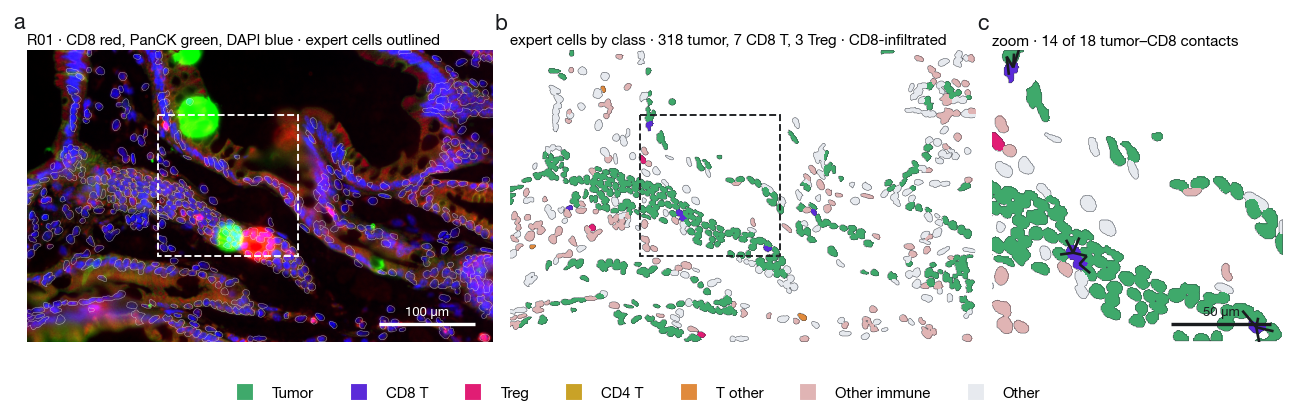

region SLIDE-0236_R01: crop at x 416-864, y 208-656 (146 µm)


In [4]:
key = FIG_REGION or max(KEYS, key=lambda k: len(REF[k]["tc"]))
image, labels, ignore = GT[key]; ref = REF[key]; H, W = labels.shape
CROP = ROI_CROP
rt = ref["t"]; pts_cd8 = rt[rt.cls == "CD8 T"][["cx", "cy"]].values; pts_treg = rt[rt.cls == "Treg"][["cx", "cy"]].values
mids = np.array([[(rt.cx[a] + rt.cx[b]) / 2, (rt.cy[a] + rt.cy[b]) / 2] for a, b in ref["tc"]]) if ref["tc"] else np.zeros((0, 2))
def inside(pts, x, y, c=None):
    c = c or CROP
    return int(((pts[:, 0] >= x) & (pts[:, 0] < x + c) & (pts[:, 1] >= y) & (pts[:, 1] < y + c)).sum()) if len(pts) else 0
def best_window(c):
    """The window of side c that holds the most of the story: contacts first, then CD8 cells, then Tregs."""
    return max(((6 * inside(mids, x, y, c) + 2 * inside(pts_cd8, x, y, c) + inside(pts_treg, x, y, c), x, y)
                for x in range(0, W - c + 1, 16) for y in range(0, H - c + 1, 16)))
print("zoom options — " + " | ".join(f"{c}px = {c * PX_UM:.0f} µm: {inside(mids, *best_window(c)[1:], c)}/{len(ref['tc'])} contacts, "
                                     f"{inside(pts_cd8, *best_window(c)[1:], c)}/{len(pts_cd8)} CD8" for c in (320, 384, 448, 512, 640, 768)))
best = best_window(CROP); x0, y0 = best[1], best[2]

def rings_of(labmap, ids):
    m = np.isin(labmap, ids).astype(np.uint8); return [c[:, 0, :].astype(float) for c in cv2.findContours(m, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)[0]]
def class_image(labmap, t):
    lut = np.ones((labmap.max() + 1, 3), np.float32)
    for i, c in t.cls.items():
        lut[i] = hexrgb(CLASS[c])
    return lut[labmap]
def draw_classes(ax, labmap, t, view=None):
    img = class_image(labmap, t); sub = img if view is None else img[view[0]:view[0] + view[2], view[1]:view[1] + view[2]]
    ax.imshow(sub, interpolation="nearest"); lm = labmap if view is None else labmap[view[0]:view[0] + view[2], view[1]:view[1] + view[2]]
    ax.add_collection(LineCollection([np.vstack([r, r[:1]]) for r in rings_of(lm, t.index.values)], colors="#40444B", linewidths=0.25))
    ax.set_axis_off()

comp = render_channels(image, MARKERS, NORMS, ("CD8", "PanCK", "DAPI")).transpose(1, 2, 0); comp = np.clip(comp * 1.6, 0, 1) ** 0.8
fig = plt.figure(figsize=(12, 3.4)); gs = fig.add_gridspec(1, 3, width_ratios=[1.6, 1.6, 1], wspace=0.04)
ax = fig.add_subplot(gs[0]); ax.imshow(comp); ax.set_axis_off()
ax.add_collection(LineCollection([np.vstack([r, r[:1]]) for r in rings_of(ref["gt_map"], ref["t"].index.values)], colors="white", linewidths=0.25, alpha=0.6))
ax.add_patch(Rectangle((x0, y0), CROP, CROP, fill=False, ec="white", lw=1.0, ls="--")); scalebar(ax, W, H, 100, color="white")
ax.set_title(f"{key.split('_')[-1]} · CD8 red, PanCK green, DAPI blue · expert cells outlined", fontsize=8, pad=3); panel_letter(ax, "a", dx=-0.005, dy=1.06)
ax = fig.add_subplot(gs[1]); draw_classes(ax, ref["gt_map"], ref["t"]); ax.add_patch(Rectangle((x0, y0), CROP, CROP, fill=False, ec=INK, lw=1.0, ls="--"))
ax.set_title(f"expert cells by class · {ref['ep']['n_tumor']} tumor, {ref['ep']['n_cd8']} CD8 T, {ref['ep']['n_treg']} Treg · {region_call(ref['ep'])}", fontsize=8, pad=3); panel_letter(ax, "b", dx=-0.005, dy=1.06)
ax = fig.add_subplot(gs[2]); draw_classes(ax, ref["gt_map"], ref["t"], view=(y0, x0, CROP))
segs = [[(ref["t"].cx[u] - x0, ref["t"].cy[u] - y0), (ref["t"].cx[v] - x0, ref["t"].cy[v] - y0)] for u, v in ref["tc"]]
ax.add_collection(LineCollection(segs, colors=INK, linewidths=1.4, zorder=3)); ax.set_xlim(0, CROP); ax.set_ylim(CROP, 0); scalebar(ax, CROP, CROP, 50)
ax.set_title(f"zoom · {inside(mids, x0, y0)} of {len(ref['tc'])} tumor–CD8 contacts", fontsize=8, pad=3); panel_letter(ax, "c", dx=-0.01, dy=1.06)
fig.legend(handles=[plt.Line2D([], [], marker="s", ls="", ms=7, color=CLASS[c], label=c) for c in ("Tumor", "CD8 T", "Treg", "CD4 T", "T other", "Other immune", "Other")], loc="lower center", ncol=7, bbox_to_anchor=(0.5, 0.02))
save(fig, "fig1_region_expert"); plt.show()
print(f"region {key}: crop at x {x0}-{x0 + CROP}, y {y0}-{y0 + CROP} ({CROP * PX_UM:.0f} µm)")

**Figure 1 — the region as the expert sees it.** (a) The tissue (CD8 red, PanCK green, DAPI blue) with every confirmed expert cell
outlined; (b) the same cells by class; (c) the zoom used in Figure 2, with the expert's tumor–CD8 contacts in black. Grey cells carry
none of the gated markers.

## 4. One zoom, four readings

{
 "region": "SLIDE-0236_R01",
 "crop": [
  416,
  208,
  448
 ],
 "columns": [
  {
   "name": "Expert",
   "run": null,
   "PQ": null,
   "contact_f1": null,
   "note": [
    "14 contacts",
    "touching 100% \u00b7 distant 0% \u00b7 Treg 0%"
   ]
  },
  {
   "name": "U-Net",
   "run": "unet_flows_s0",
   "PQ": 0.707,
   "contact_f1": 0.4,
   "note": [
    "5 kept \u00b7 9 lost \u00b7 7 new",
    "touching 88% \u00b7 distant 12% \u00b7 Treg 0%"
   ]
  },
  {
   "name": "KODIAK B/16",
   "run": "kodiakb_flows_s0",
   "PQ": 0.708,
   "contact_f1": 0.58,
   "note": [
    "9 kept \u00b7 5 lost \u00b7 5 new",
    "touching 100% \u00b7 distant 0% \u00b7 Treg 0%"
   ]
  },
  {
   "name": "Cellpose, adapted",
   "run": "cellpose_ft_s0",
   "PQ": 0.75,
   "contact_f1": 0.41,
   "note": [
    "6 kept \u00b7 8 lost \u00b7 10 new",
    "touching 100% \u00b7 distant 0% \u00b7 Treg 0%"
   ]
  }
 ]
}


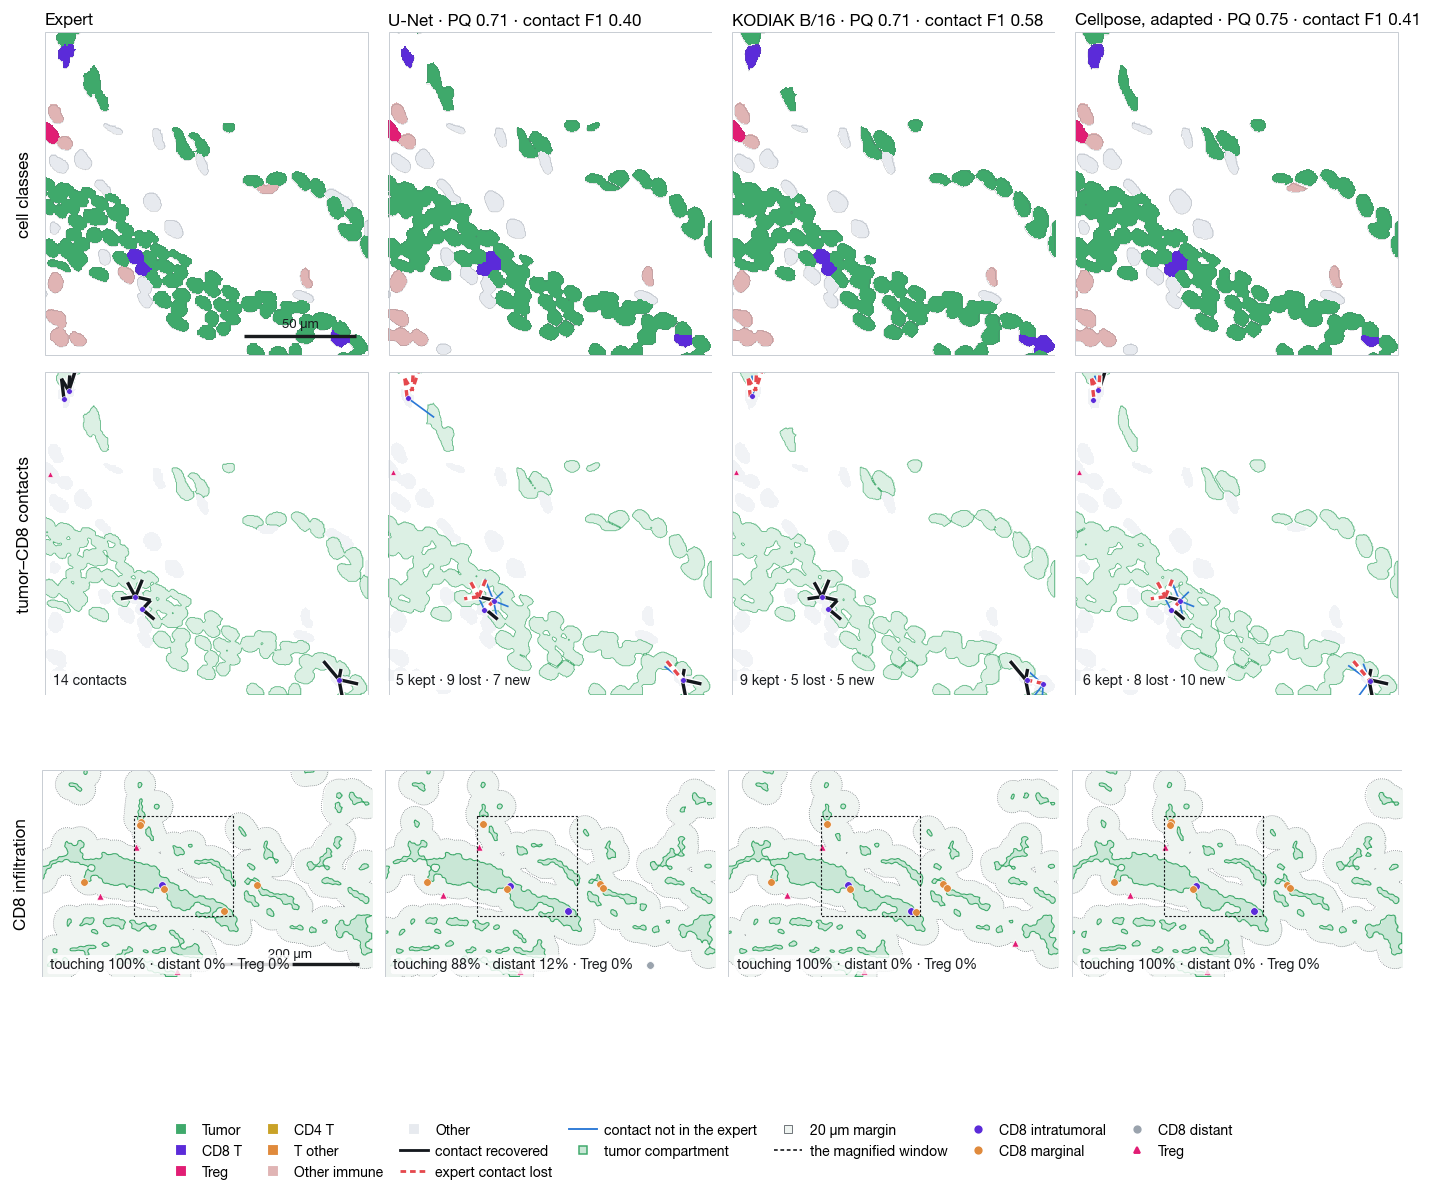

In [5]:
show = [m for m in SHOW if m in BY]
cols = [{"name": "Expert", "a": ref, "map": ref["gt_map"], "fr": None}]
for m in show:
    rn = BY[m][0]["run"]
    o = instance_outcomes(labels, np.load(PRED / rn / f"{key}.npz")["pred"].astype(np.int32), ignore=ignore, thr=0.5)
    cols.append({"name": lab(m), "a": RUN[(rn, key)], "map": o["pred"], "fr": FID[(FID.run == rn) & (FID.region == key)].iloc[0], "run": rn})

# ---- what every panel draws, computed once per column -------------------------------------------------------------
def seg_of(tab, u, v):
    return [(tab.cx[u] - x0, tab.cy[u] - y0), (tab.cx[v] - x0, tab.cy[v] - y0)]
def mid_in(s):
    return 0 <= (s[0][0] + s[1][0]) / 2 < CROP and 0 <= (s[0][1] + s[1][1]) / 2 < CROP
for c in cols:
    a = c["a"]; t = a["t"]
    c["crop"] = np.where(np.isin(c["map"], t.index.values), c["map"], 0)[y0:y0 + CROP, x0:x0 + CROP]
    c["compc"] = a["comp"][y0:y0 + CROP, x0:x0 + CROP]
    c["dist"] = (ndi.distance_transform_edt(~a["comp"]) * PX_UM) if a["comp"].any() else None
    c["distc"] = None if c["dist"] is None else c["dist"][y0:y0 + CROP, x0:x0 + CROP]
    if c["fr"] is None:                                                    # the expert: its own contacts, nothing to compare
        c["rec"], c["lost"], c["new"] = [s for s in (seg_of(t, u, v) for u, v in a["tc"]) if mid_in(s)], [], []
    else:                                                                  # a method: expert contacts kept / lost, plus its own extras
        pairs = a["pairs"]; rt = ref["t"]; rec, lost = [], []
        for u, v in ref["tc"]:
            pu, pv = pairs.get(u), pairs.get(v)
            ok = (pu is not None and pv is not None and pu != pv and pu in t.index and pv in t.index
                  and {t.cls[pu], t.cls[pv]} == {"Tumor", "CD8 T"} and (min(pu, pv), max(pu, pv)) in a["E"])
            (rec if ok else lost).append(seg_of(rt, u, v))
        inv = {v_: k_ for k_, v_ in pairs.items()}
        new = [seg_of(t, u, v) for u, v in a["tc"]
               if not (inv.get(u) is not None and inv.get(v) is not None and (min(inv[u], inv[v]), max(inv[u], inv[v])) in ref["tc"])]
        c["rec"], c["lost"], c["new"] = [s for s in rec if mid_in(s)], [s for s in lost if mid_in(s)], [s for s in new if mid_in(s)]
    ep = a["ep"]
    c["note"] = [f"{len(c['rec'])} contacts" if c["fr"] is None else f"{len(c['rec'])} kept · {len(c['lost'])} lost · {len(c['new'])} new",
                 f"touching {100 * ep['cd8_touching_frac']:.0f}% · distant {100 * ep['cd8_distant_frac']:.0f}% · Treg {100 * ep['cd8_regulated_frac']:.0f}%"]

# ---- one painter per row, used both for the notebook figure and for the paper's panels ------------------------------
def frame(ax, w=None, h=None):
    w, h = w or CROP, h or CROP
    ax.set_xlim(0, w); ax.set_ylim(h, 0); ax.set_axis_off()
    ax.add_patch(Rectangle((0.5, 0.5), w - 1, h - 1, fill=False, ec="#C6CBD2", lw=0.5, zorder=20))
def chip_note(ax, text, size=4.6):
    ax.text(0.025, 0.025, text, transform=ax.transAxes, fontsize=size, color=INK, va="bottom", ha="left", zorder=21,
            bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.82))
def paint_classes(ax, c):
    t = c["a"]["t"]; lut = np.ones((int(c["crop"].max()) + 1, 3), np.float32)
    for i, cl in t.cls.items():
        if i < len(lut):
            lut[i] = hexrgb(CLASS[cl])
    ax.imshow(lut[c["crop"]], interpolation="nearest")
    ax.add_collection(LineCollection([np.vstack([r, r[:1]]) for r in rings_of(c["crop"], t.index.values)], colors="#5D646D", linewidths=0.2, alpha=0.55))
    frame(ax)
def paint_contacts(ax, c):
    t = c["a"]["t"]; m_tum = np.isin(c["crop"], t.index[t.cls == "Tumor"].values)
    base = np.ones((CROP, CROP, 3), np.float32)
    base[c["crop"] > 0] = hexrgb(FILL["Other"]); base[m_tum] = hexrgb(FILL["Tumor"])
    ax.imshow(base, interpolation="nearest")
    ax.add_collection(LineCollection([np.vstack([r, r[:1]]) for r in rings_of(m_tum.astype(np.int32), [1])], colors=COMP_EDGE, linewidths=0.4, alpha=0.85))
    for segs, col, lw, ls, z, halo in ((c["new"], CONTACT["new"], 0.9, "solid", 4, False),
                                       (c["rec"], CONTACT["recovered"], 1.8, "solid", 6, True),
                                       (c["lost"], CONTACT["lost"], 1.8, (0, (2, 1.4)), 8, True)):
        if not segs:
            continue
        if halo:
            ax.add_collection(LineCollection(segs, colors="white", linewidths=lw + 1.4, zorder=z - 1))
        ax.add_collection(LineCollection(segs, colors=col, linewidths=lw, linestyles=ls, zorder=z))
    cd8 = t[t.cls == "CD8 T"]; ax.scatter(cd8.cx - x0, cd8.cy - y0, s=9, c=CLASS["CD8 T"], lw=0.3, edgecolor="white", zorder=10)
    trg = t[t.cls == "Treg"]; ax.scatter(trg.cx - x0, trg.cy - y0, s=9, c=CLASS["Treg"], marker="^", lw=0.3, edgecolor="white", zorder=10)
    frame(ax)
def paint_infiltration(ax, c):
    """The WHOLE region, three filled zones: the tumor compartment, its 20 µm margin, everything beyond. Infiltration
    and exclusion are regional reads -- the percentages under the panel are the region's -- so this row zooms out and
    marks the window the two rows above show."""
    t = c["a"]["t"]; comp = c["a"]["comp"]; bg = np.ones((H, W, 3), np.float32)
    if c["dist"] is not None:
        bg[c["dist"] <= MARGIN_UM] = hexrgb(COMP_MARGIN)
    bg[comp] = hexrgb(COMP_FILL)
    ax.imshow(bg, interpolation="nearest")
    if c["dist"] is not None:
        ax.contour(c["dist"], levels=[MARGIN_UM], colors=[MUTED], linewidths=0.4, linestyles="dotted")   # contour takes named styles only
    ax.add_collection(LineCollection([np.vstack([r, r[:1]]) for r in rings_of(comp.astype(np.int32), [1])], colors=COMP_EDGE, linewidths=0.55))
    for z_, col in ZONE.items():
        s_ = t[(t.zone == z_) & (t.cls == "CD8 T")]
        ax.scatter(s_.cx, s_.cy, s=17, c=col, lw=0.4, edgecolor="white", zorder=3)
    trg = t[t.cls == "Treg"]; ax.scatter(trg.cx, trg.cy, s=15, c=CLASS["Treg"], marker="^", lw=0.4, edgecolor="white", zorder=4)
    ax.add_patch(Rectangle((x0, y0), CROP, CROP, fill=False, ec=INK, lw=0.6, ls=(0, (2.2, 1.6)), zorder=15))
    frame(ax, W, H)
PAINT = [paint_classes, paint_contacts, paint_infiltration]
ROW = ["cell classes", "tumor–CD8 contacts", "CD8 infiltration"]

# ---- the paper's copies: ONE PDF PER PANEL at its final print size, headers and legend typeset by main.tex ----------
for j, c in enumerate(cols):
    for i, painter in enumerate(PAINT):
        f_ = plt.figure(figsize=(ROI_PANEL, ROI_PANEL)); ax_ = f_.add_axes([0, 0, 1, 1])
        painter(ax_, c)
        if i:
            chip_note(ax_, c["note"][i - 1])
        if j == 0 and i == 0:
            scalebar(ax_, CROP, CROP, 50, size=4.6)
        if j == 0 and i == 2:
            scalebar(ax_, W, H, 200, size=4.6)
        f_.savefig(PAPERFIG / f"roi_c{j + 1}r{i + 1}.pdf"); plt.close(f_)
lg = plt.figure(figsize=(4 * ROI_PANEL + 0.36, 0.66))
H1 = [plt.Line2D([], [], marker="s", ls="", ms=4.2, color=CLASS[c_], label=c_) for c_ in ("Tumor", "CD8 T", "Treg", "CD4 T", "T other", "Other immune", "Other")]
H2 = [plt.Line2D([], [], color=CONTACT["recovered"], lw=1.5, label="contact recovered"), plt.Line2D([], [], color=CONTACT["lost"], lw=1.5, ls=(0, (2, 1.4)), label="expert contact lost"),
      plt.Line2D([], [], color=CONTACT["new"], lw=1.0, label="contact not in the expert")]
H3 = [plt.Line2D([], [], marker="s", ls="", ms=4.2, mfc=COMP_FILL, mec=COMP_EDGE, mew=0.8, label="tumor compartment"),
      plt.Line2D([], [], marker="s", ls="", ms=4.2, mfc=COMP_MARGIN, mec=MUTED, mew=0.5, label=f"{MARGIN_UM:.0f} µm margin"),
      plt.Line2D([], [], color=INK, lw=0.9, ls=(0, (2.2, 1.6)), label="the magnified window")] + \
     [plt.Line2D([], [], marker="o", ls="", ms=3.4, color=col, label=f"CD8 {z_}") for z_, col in ZONE.items()] + \
     [plt.Line2D([], [], marker="^", ls="", ms=3.4, color=CLASS["Treg"], label="Treg")]
for hs, yy, nc in ((H1, 1.00, 7), (H2, 0.66, 3), (H3, 0.34, 6)):
    lg.add_artist(lg.legend(hs, [h.get_label() for h in hs], loc="upper center", bbox_to_anchor=(0.5, yy), ncol=nc, fontsize=5.8,
                            handlelength=1.2, handletextpad=0.4, columnspacing=1.1, borderpad=0.0, borderaxespad=0.0))
lg.savefig(PAPERFIG / "roi_legend.pdf", bbox_inches="tight", pad_inches=0.015); plt.close(lg)
hdr = {"region": key, "crop": [int(x0), int(y0), CROP], "columns": [
    {"name": c["name"], "run": c.get("run"), "PQ": None if c["fr"] is None else round(float(c["fr"].PQ), 3),
     "contact_f1": None if c["fr"] is None else round(float(c["fr"].contact_f1), 2), "note": c["note"]} for c in cols]}
(PAPERFIG / "roi.json").write_text(json.dumps(hdr, indent=1))
print(json.dumps(hdr, indent=1))

# ---- the notebook's own overview, from the same painters -----------------------------------------------------------
fig = plt.figure(figsize=(3.05 * len(cols) + 0.8, 3 * 3.05 + 0.5))
gs = fig.add_gridspec(3, len(cols), wspace=0.04, hspace=0.05)
for j, c in enumerate(cols):
    for i, painter in enumerate(PAINT):
        ax = fig.add_subplot(gs[i, j]); painter(ax, c)
        if i == 0:
            ax.set_title(c["name"] if c["fr"] is None else f"{c['name']} · PQ {c['fr'].PQ:.2f} · contact F1 {c['fr'].contact_f1:.2f}", fontsize=9, pad=4)
        else:
            chip_note(ax, c["note"][i - 1], size=7.5)
        if j == 0:
            ax.text(-0.04, 0.5, ROW[i], transform=ax.transAxes, rotation=90, va="center", ha="right", fontsize=9, fontweight="bold")
            if i == 0:
                scalebar(ax, CROP, CROP, 50)
            if i == 2:
                scalebar(ax, W, H, 200)
fig.legend(handles=H1 + H2 + H3, loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.01), fontsize=7.5, handletextpad=0.5, columnspacing=1.2)
save(fig, "fig2_roi_methods"); plt.show()


**Figure 2 — one zoom, the expert and three methods.** Columns: the expert reference, the U-Net baseline, the foundation model
(MxIF-SSL B/16) that ties with it on PQ, and Cellpose adapted (seed 0 of each), each headed by its Panoptic Quality and tumor–CD8
contact F1 on this region (U-Net 0.71 / 0.40, MxIF-SSL B/16 0.71 / 0.58, Cellpose 0.75 / 0.41; the window holds 14 of the region's
18 expert contacts, of which they keep 5, 9 and 6). Rows: **cell classes** on white; **tumor–CD8 contacts** — black where the method
recovers the expert's contact, red dashed where it loses it (a cell missed or merged, a class changed, adjacency broken), blue where the
method reports a contact the expert does not have; **CD8 infiltration** — the tumor compartment (green), its 20 µm margin (dotted), and
every CD8 cell colored by where it sits, Tregs as triangles. Reading down a column is the biology; reading across a row is what the
boundaries change about it. The same three PQ values at region scale give 0.40, 0.58 and 0.41 at contact scale; over the six regions
the order of the first two is reversed (Table 2: U-Net 0.58, MxIF-SSL B/16 0.50).


## 5. Segmentation quality against biological fidelity

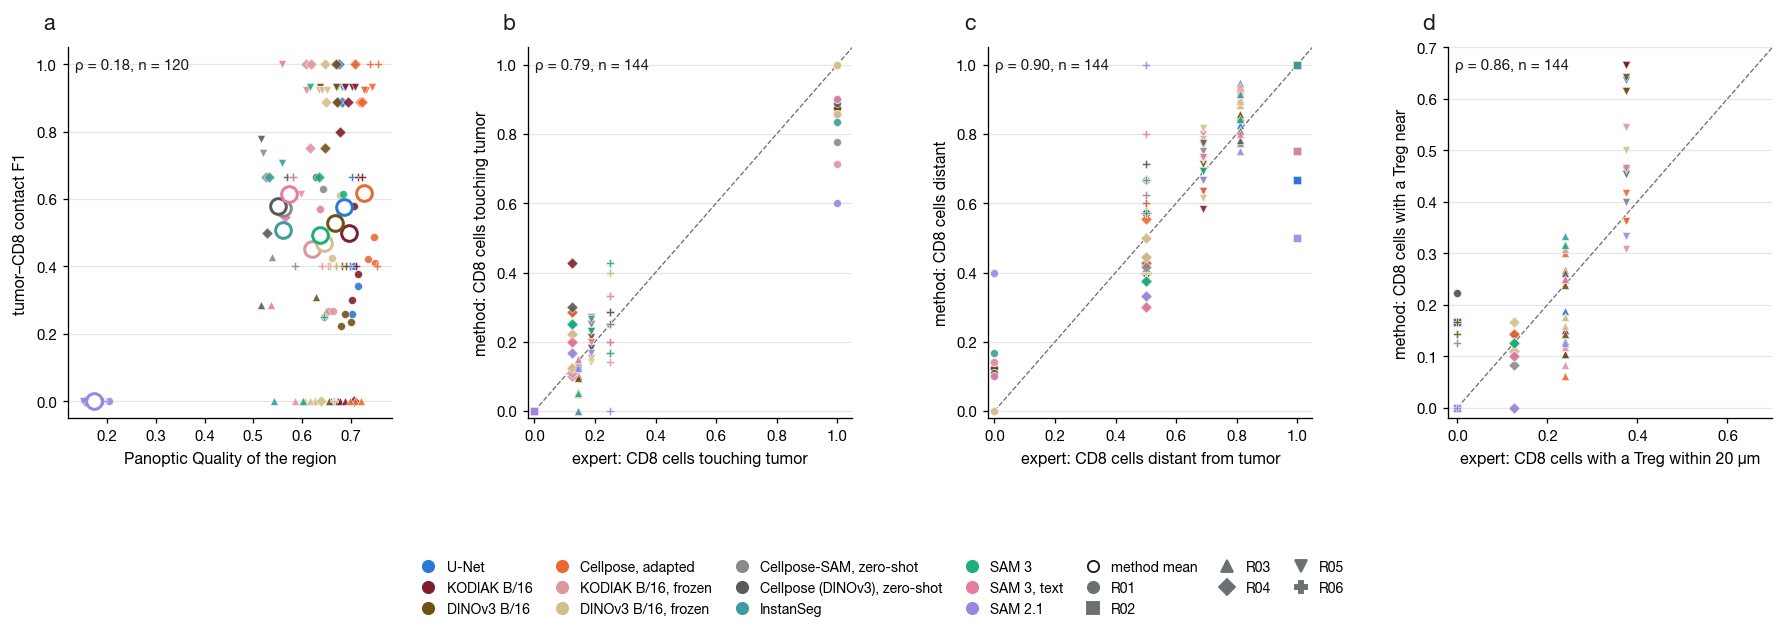

,Expert,U-Net,KODIAK B/16,DINOv3 B/16,"Cellpose, adapted","KODIAK B/16, frozen","DINOv3 B/16, frozen","Cellpose-SAM, zero-shot","Cellpose (DINOv3), zero-shot",InstanSeg,SAM 3,"SAM 3, text",SAM 2.1
R01,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated,CD8-infiltrated
R02,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded
R03,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded
R04,immune-excluded,immune-excluded,CD8-infiltrated,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,CD8-infiltrated,immune-excluded,immune-excluded,immune-excluded,immune-excluded
R05,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded,immune-excluded
R06,immune-excluded,CD8-infiltrated,immune-excluded,CD8-infiltrated,immune-excluded,CD8-infiltrated,CD8-infiltrated,immune-excluded,immune-excluded,immune-excluded,CD8-infiltrated,immune-excluded,immune-excluded


In [6]:
FID["cd8_touching_frac_ref"] = FID.region.map({k: REF[k]["ep"]["cd8_touching_frac"] for k in KEYS}); FID["cd8_touching_frac_run"] = FID.cd8_touching_frac_err + FID.cd8_touching_frac_ref
FID["cd8_distant_frac_ref"] = FID.region.map({k: REF[k]["ep"]["cd8_distant_frac"] for k in KEYS}); FID["cd8_distant_frac_run"] = FID.cd8_distant_frac_err + FID.cd8_distant_frac_ref
FID["cd8_regulated_frac_ref"] = FID.region.map({k: REF[k]["ep"]["cd8_regulated_frac"] for k in KEYS}); FID["cd8_regulated_frac_run"] = FID.cd8_regulated_frac_err + FID.cd8_regulated_frac_ref
REGMARK = dict(zip(KEYS, ["o", "s", "^", "D", "v", "P"]))
def scat(ax, x, y, xlabel, ylabel, letter, identity=False, means=True):
    for m in METHODS:
        d = FID[FID.method == m]
        for k, dk in d.groupby("region"):
            ax.scatter(dk[x], dk[y], s=18, color=MCOLOR[m], marker=REGMARK[k], lw=0.3, edgecolor="white", zorder=3, alpha=0.9)
        if means:
            ax.scatter(d[x].mean(), d[y].mean(), s=70, facecolor="white", edgecolor=MCOLOR[m], lw=1.6, zorder=4)
    ok = FID[[x, y]].dropna(); rho, p = spearmanr(ok[x], ok[y]) if len(ok) > 3 else (np.nan, np.nan)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.text(0.02, 0.97, f"ρ = {rho:.2f}, n = {len(ok)}", transform=ax.transAxes, va="top", fontsize=8, color=INK); ygrid(ax); panel_letter(ax, letter)
    if identity:
        lo, hi = 0, max(ok[x].max(), ok[y].max()) * 1.05; ax.plot([lo, hi], [lo, hi], color=MUTED, lw=0.7, ls="--", zorder=1); ax.set_xlim(lo - 0.02, hi); ax.set_ylim(lo - 0.02, hi)
    return rho
fig, ax = plt.subplots(1, 4, figsize=(13.5, 4.5), gridspec_kw=dict(wspace=0.42))
fig.subplots_adjust(left=0.055, right=0.99, top=0.95, bottom=0.34)   # room for the legend BELOW the x labels
r1 = scat(ax[0], "PQ", "contact_f1", "Panoptic Quality of the region", "tumor–CD8 contact F1", "a")
r2 = scat(ax[1], "cd8_touching_frac_ref", "cd8_touching_frac_run", "expert: CD8 cells touching tumor", "method: CD8 cells touching tumor", "b", identity=True, means=False)
r3 = scat(ax[2], "cd8_distant_frac_ref", "cd8_distant_frac_run", "expert: CD8 cells distant from tumor", "method: CD8 cells distant", "c", identity=True, means=False)
r4 = scat(ax[3], "cd8_regulated_frac_ref", "cd8_regulated_frac_run", "expert: CD8 cells with a Treg within 20 µm", "method: CD8 cells with a Treg near", "d", identity=True, means=False)
h = [plt.Line2D([], [], marker="o", ls="", color=MCOLOR[m], label=lab(m)) for m in METHODS] + [plt.Line2D([], [], marker="o", ls="", mfc="white", mec=INK, label="method mean")]
h += [plt.Line2D([], [], marker=REGMARK[k], ls="", color=MUTED, label=k.split("_")[-1]) for k in KEYS]
fig.legend(handles=h, loc="lower center", ncol=7, bbox_to_anchor=(0.5, 0.005), fontsize=7.5,
           handletextpad=0.3, columnspacing=1.1, borderaxespad=0.0)
save(fig, "fig3_pq_vs_fidelity"); plt.show()
calls = pd.DataFrame({lab(m): [region_call(RUN[(BY[m][0]["run"], k)]["ep"]) for k in KEYS] for m in METHODS}, index=[k.split("_")[-1] for k in KEYS])
calls.insert(0, "Expert", [region_call(REF[k]["ep"]) for k in KEYS]); calls

**Figure 3 — does segmentation quality predict the biology?** One point per run × region (marker shape = region, color = method; open
circles = method means). (a) Panoptic Quality against the fidelity of tumor–CD8 contacts. (b–d) Each method's biological score against the
expert's, with the identity line: CD8 cells touching tumor (infiltration), CD8 cells distant from tumor (exclusion), CD8 cells with a Treg
within 20 µm (regulation). The table gives every region's call, expert against each method's first seed.

## 6. Not all errors are equal

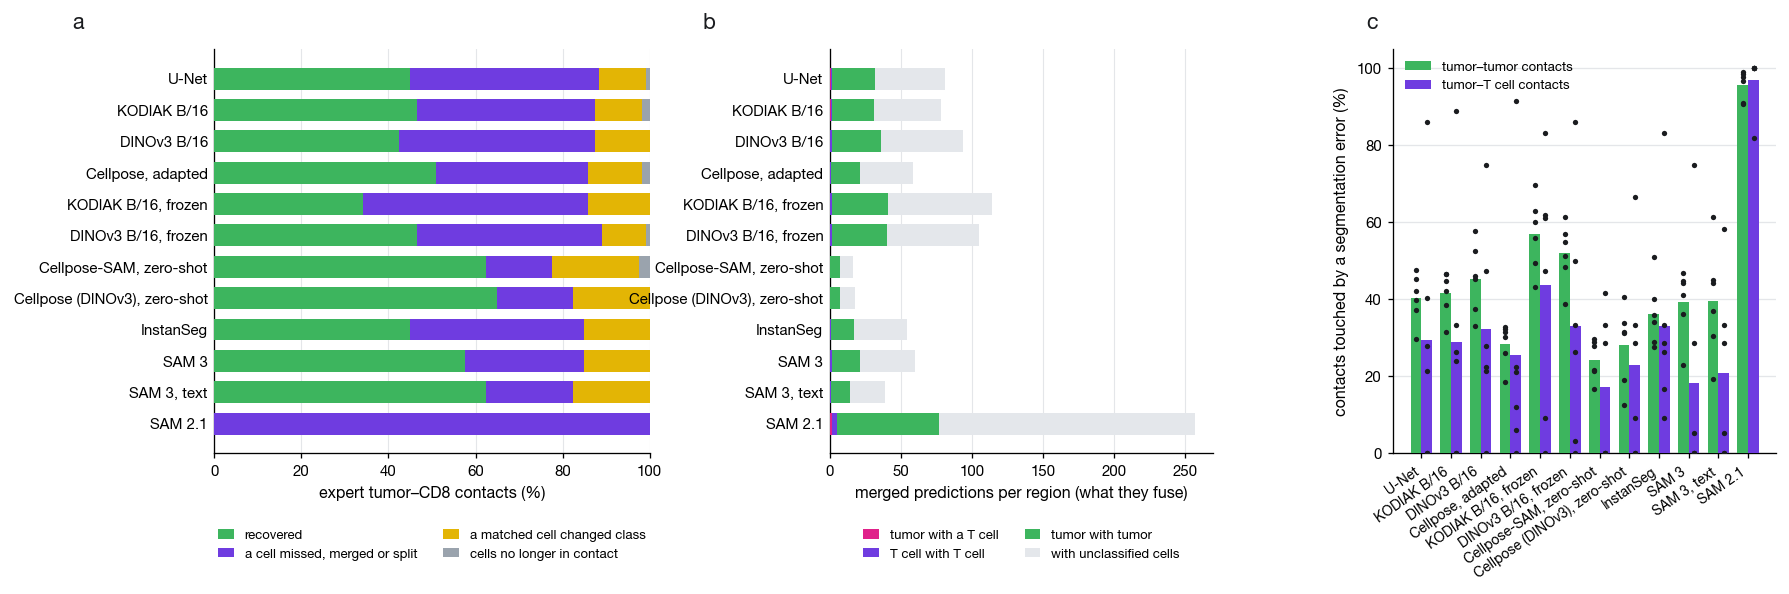

,predictor,Spearman with contact F1 (all points),within region (mean)
0,PQ,0.18,0.18
1,Dice,0.19,0.22
2,F1,0.22,0.24
3,E_homotypic,-0.20,-0.28
4,E_interface_other,-0.39,-0.23
5,E_interface,-0.78,-0.63


In [7]:
why_cols = ["why_recovered", "why_cell_not_matched", "why_class_changed", "why_adjacency_lost"]
WHY_LABEL = {"why_recovered": "recovered", "why_cell_not_matched": "a cell missed, merged or split", "why_class_changed": "a matched cell changed class", "why_adjacency_lost": "cells no longer in contact"}
WHY_COLOR = {"why_recovered": "#3DB55E", "why_cell_not_matched": "#6F3CE0", "why_class_changed": "#E3B505", "why_adjacency_lost": "#9AA3AD"}
per_run = FID.groupby(["method", "run"])[why_cols + ["merge_tumor_tumor", "merge_tumor_T_cell", "merge_T_cell_T_cell", "merge_other", "n_expert_contacts"]].sum().reset_index()
why = per_run.groupby("method")[why_cols].mean().reindex(METHODS); why = 100 * why.div(why.sum(1), axis=0)
mg = per_run.groupby("method")[["merge_tumor_tumor", "merge_tumor_T_cell", "merge_T_cell_T_cell", "merge_other"]].mean().reindex(METHODS)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1.1, 1.1], wspace=0.45))
fig.subplots_adjust(left=0.10, right=0.99, top=0.95, bottom=0.30)    # the legends and the rotated names need real space
y = np.arange(len(METHODS))[::-1]; left = np.zeros(len(METHODS))
for c in why_cols:
    ax[0].barh(y, why[c].values, left=left, color=WHY_COLOR[c], height=0.7, zorder=3, label=WHY_LABEL[c]); left += why[c].values
ax[0].set_yticks(y, [lab(m) for m in METHODS]); ax[0].set_xlabel("expert tumor–CD8 contacts (%)"); ax[0].set_xlim(0, 100); ax[0].tick_params(axis="y", length=0)
ax[0].grid(axis="x", color=GRID, lw=0.6, zorder=0); ax[0].set_axisbelow(True); ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=7,
                                        frameon=False, handlelength=1.2); panel_letter(ax[0], "a", dx=-0.3)
MG_LABEL = {"merge_tumor_T_cell": "tumor with a T cell", "merge_T_cell_T_cell": "T cell with T cell", "merge_tumor_tumor": "tumor with tumor", "merge_other": "with unclassified cells"}
MG_COLOR = {"merge_tumor_T_cell": "#E0218A", "merge_T_cell_T_cell": "#6F3CE0", "merge_tumor_tumor": "#3DB55E", "merge_other": "#E4E7EB"}
left = np.zeros(len(METHODS))
for c in MG_LABEL:
    ax[1].barh(y, mg[c].values / len(KEYS), left=left, color=MG_COLOR[c], height=0.7, zorder=3, label=MG_LABEL[c]); left += mg[c].values / len(KEYS)
ax[1].set_yticks(y, [lab(m) for m in METHODS]); ax[1].set_xlabel("merged predictions per region (what they fuse)"); ax[1].tick_params(axis="y", length=0)
ax[1].grid(axis="x", color=GRID, lw=0.6, zorder=0); ax[1].set_axisbelow(True); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=7,
                                        frameon=False, handlelength=1.2); panel_letter(ax[1], "b", dx=-0.3)
g = FID.groupby("method")[["E_homotypic", "E_interface"]].mean().reindex(METHODS)
x = np.arange(len(METHODS)); w = 0.36
ax[2].bar(x - w / 2, 100 * g.E_homotypic, w, color="#3DB55E", zorder=3, label="tumor–tumor contacts"); ax[2].bar(x + w / 2, 100 * g.E_interface, w, color="#6F3CE0", zorder=3, label="tumor–T cell contacts")
for i, m in enumerate(METHODS):
    d = FID[FID.method == m].groupby("region")[["E_homotypic", "E_interface"]].mean()
    ax[2].scatter(np.full(len(d), i - w / 2), 100 * d.E_homotypic, s=8, color=INK, zorder=4, lw=0); ax[2].scatter(np.full(len(d), i + w / 2), 100 * d.E_interface, s=8, color=INK, zorder=4, lw=0)
ax[2].set_xticks(x, [lab(m) for m in METHODS], rotation=35, ha="right", fontsize=7.5); ax[2].set_ylabel("contacts touched by a segmentation error (%)"); ygrid(ax[2]); ax[2].legend(loc="upper left", fontsize=7); panel_letter(ax[2], "c")
save(fig, "fig4_errors"); plt.show()
preds = ["PQ", "Dice", "F1", "E_homotypic", "E_interface_other", "E_interface"]
rows = []
for p_ in preds:
    ok = FID[[p_, "contact_f1"]].dropna(); rho_all = spearmanr(ok[p_], ok.contact_f1)[0]
    within = [spearmanr(d[p_], d.contact_f1)[0] for k, d in FID.groupby("region") if d[[p_, "contact_f1"]].dropna().shape[0] > 4]
    rows.append({"predictor": p_, "Spearman with contact F1 (all points)": rho_all, "within region (mean)": np.nanmean(within)})
pd.DataFrame(rows).round(2)

**Figure 4 — where the ecosystem is lost.** (a) Why an expert tumor–CD8 contact is not recovered, per method: mostly because one of
its two cells is missed, merged or split (35–52 % of the expert contacts for the trained rows); a matched cell that changed class
accounts for 10–20 %, a broken adjacency for at most 2 %. (b) What the merged predictions fuse: tumor with tumor (harmless for the
tumor–immune ecosystem, 20–39 per region for the trained rows) against tumor with a T cell (destroys a heterotypic interface; at most
0.6 per region for the trained rows). (c) The share of expert contacts touched by a segmentation error, tumor–tumor against tumor–T cell, per method with the
six regions as dots. The table ranks the predictors of contact fidelity: the interface rate on the endpoint's own contacts is
near-circular (`E_interface`, ρ = −0.78); the fair test uses contacts with other T cells (`E_interface_other`, 25 contacts on this
slide), which reaches ρ = −0.39 against 0.18 for PQ — the right direction, on too few events to decide.


## 6b. How much the endpoint can carry

The tumor--CD8 endpoint is spatially explicit and biologically the right question, but on this slide it rests on few events: the
expert's six regions hold **61 CD8 cells and 40 tumor--CD8 contacts**, between 0 and 18 per region, and R02 has none at all, so its
contact F1 is undefined. A correlation computed over run x region points is therefore dominated by sampling noise, and a weak
Spearman against PQ is not by itself evidence that PQ fails to predict the biology.

This section separates the two. Every method's contacts are **pooled over all six regions** into one recall, precision and F1, so
each method contributes a single well-estimated point instead of six noisy ones, and the pooled F1 carries a bootstrap interval
over contacts. The predictor comparison is then repeated on those pooled values. A claim that survives both the per-region and the
pooled view is safe; one that appears only in the per-region view is noise.

In [8]:
rng = np.random.default_rng(0)

def pooled(df):
    """One recall / precision / F1 per method from the summed contact counts, with a bootstrap interval over contacts."""
    g = df.groupby("run")[["n_rec_contacts", "n_expert_contacts", "n_run_contacts", "n_prec_hits"]].sum()
    rec = g.n_rec_contacts.sum() / max(g.n_expert_contacts.sum(), 1)
    prec = g.n_prec_hits.sum() / max(g.n_run_contacts.sum(), 1)
    f1 = 2 * rec * prec / max(rec + prec, 1e-9)
    per_run = 2 * g.n_rec_contacts / np.maximum(g.n_expert_contacts + g.n_run_contacts, 1)
    bs = [np.mean(rng.choice(per_run.values, len(per_run), replace=True)) for _ in range(4000)] if len(per_run) > 1 else [f1]
    return pd.Series({"pooled_recall": rec, "pooled_precision": prec, "pooled_F1": f1,
                      "lo": np.percentile(bs, 2.5), "hi": np.percentile(bs, 97.5),
                      "contacts": int(g.n_expert_contacts.sum()), "seeds": df.run.nunique()})

POOL = FID.groupby("method").apply(pooled, include_groups=False).reindex(METHODS)
POOL["PQ"] = FID.groupby("method").PQ.mean().reindex(METHODS)
POOL["E_interface"] = FID.groupby("method").E_interface.mean().reindex(METHODS)
POOL["E_homotypic"] = FID.groupby("method").E_homotypic.mean().reindex(METHODS)
POOL["E_interface_other"] = FID.groupby("method").E_interface_other.mean().reindex(METHODS)
POOL["Dice"] = FID.groupby("method").Dice.mean().reindex(METHODS)

print(f"pooled over {int(POOL.contacts.iloc[0] / POOL.seeds.iloc[0])} expert tumor-CD8 contacts x {len(KEYS)} regions, per method\n")
print(POOL[["pooled_F1", "lo", "hi", "pooled_recall", "pooled_precision", "PQ", "E_interface"]]
      .rename(index=lab).round(3).to_string())

print("\nSpearman with the endpoint, per-region points vs pooled method-level points:")
rows = []
for pname in ("PQ", "Dice", "E_homotypic", "E_interface", "E_interface_other"):
    ok = FID[[pname, "contact_f1"]].dropna()
    rows.append({"predictor": pname, "per-region rho": spearmanr(ok[pname], ok.contact_f1)[0],
                 "n points": len(ok), "pooled rho": spearmanr(POOL[pname], POOL.pooled_F1)[0], "n methods": len(POOL)})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nRead. A predictor that ranks methods the same way in both views is real; one that only appears in the per-region"
      "\nview is sampling noise from 0-18 contacts a region. Note that E_interface COUNTS the tumor-CD8 contacts the endpoint"
      "\nis built from, so it is partly circular and must not be the headline number: E_interface_other, which excludes them,"
      "\nis the fair comparison against PQ.")

pooled over 40 expert tumor-CD8 contacts x 6 regions, per method

                              pooled_F1     lo     hi  pooled_recall  pooled_precision     PQ  E_interface
method                                                                                                    
U-Net                             0.493  0.457  0.521          0.450             0.545  0.687        0.293
KODIAK B/16                       0.461  0.390  0.561          0.467             0.455  0.697        0.287
DINOv3 B/16                       0.453  0.432  0.486          0.425             0.486  0.667        0.323
Cellpose, adapted                 0.545  0.507  0.595          0.508             0.587  0.728        0.255
KODIAK B/16, frozen               0.416  0.364  0.462          0.342             0.532  0.621        0.438
DINOv3 B/16, frozen               0.514  0.412  0.568          0.467             0.571  0.645        0.331
Cellpose-SAM, zero-shot           0.610  0.610  0.610          0.625          

## 7. The endpoint fingerprint of every method

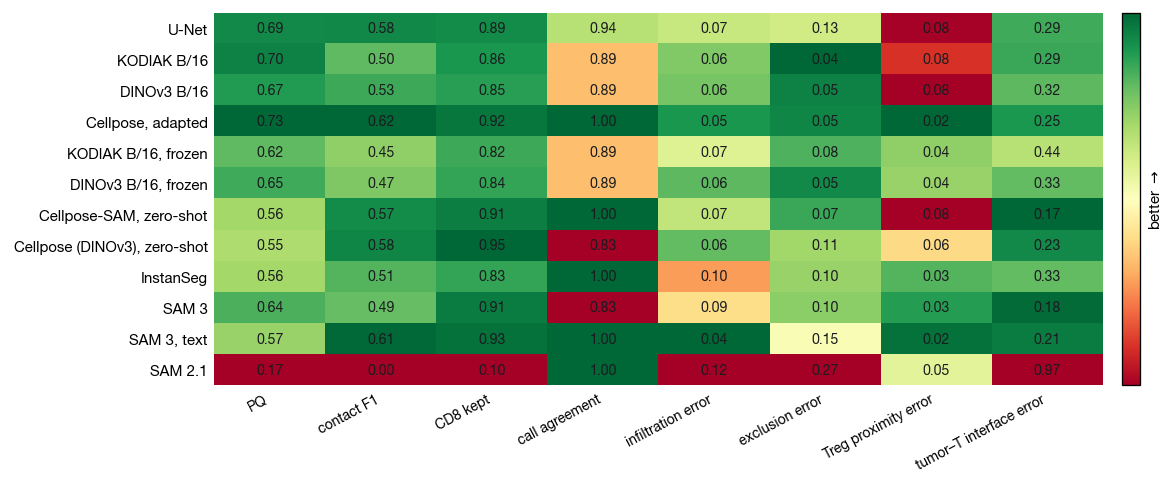

In [9]:
FP = pd.DataFrame({
    "PQ": FID.groupby("method").PQ.mean(), "contact F1": FID.groupby("method").contact_f1.mean(),
    "CD8 kept": FID.groupby("method").cd8_matched_frac.mean(), "call agreement": FID.groupby("method").call_agree.mean(),
    "infiltration error": FID.groupby("method").cd8_touching_frac_err.apply(lambda s: s.abs().mean()),
    "exclusion error": FID.groupby("method").cd8_distant_frac_err.apply(lambda s: s.abs().mean()),
    "Treg proximity error": FID.groupby("method").cd8_regulated_frac_err.apply(lambda s: s.abs().mean()),
    "tumor–T interface error": FID.groupby("method").E_interface.mean()}).reindex(METHODS)
FP.index = [lab(m) for m in FP.index]
better_high = ["PQ", "contact F1", "CD8 kept", "call agreement"]
norm = FP.copy()
for c in FP.columns:
    v = FP[c]; norm[c] = (v - v.min()) / max(v.max() - v.min(), 1e-9); norm[c] = norm[c] if c in better_high else 1 - norm[c]
fig, ax = plt.subplots(figsize=(9, 4.0))
fig.subplots_adjust(left=0.17, right=0.94, top=0.97, bottom=0.28)   # the rotated column names were clipped
im = ax.imshow(norm.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
for i in range(FP.shape[0]):
    for j, c in enumerate(FP.columns):
        ax.text(j, i, f"{FP.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=INK)
ax.set_xticks(range(FP.shape[1]), FP.columns, rotation=28, ha="right", fontsize=7.5); ax.set_yticks(range(FP.shape[0]), FP.index)
for s_ in ("top", "right", "left", "bottom"): ax.spines[s_].set_visible(False)
ax.tick_params(length=0); cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.set_label(r"better $\rightarrow$", fontsize=8); cb.set_ticks([])
save_panels(fig, "fingerprint", [ax])
save(fig, "fig5_fingerprint"); plt.show()

**Figure 5 — one row per method.** Segmentation quality (PQ), the primary endpoint (contact F1), the share of expert CD8 cells the method
keeps, the agreement of its region calls, the absolute errors of the three biological scores, and the tumor–T interface error rate; color
is rank within each column (green = better). The U-Net and the MxIF-SSL B/16 fine-tune are 0.01 apart on PQ and 0.08 apart on contact
F1, in the opposite direction; the zero-shot Cellpose rows sit among the lowest PQ values (0.55–0.56) yet match the U-Net on contact F1 (0.57–0.58).


## 8. What the numbers say

In [10]:
summ2 = FID.groupby("method").contact_f1.mean().reindex(METHODS)
print(f"primary endpoint (tumor–CD8 contact F1): " + ", ".join(f"{lab(m)} {v:.2f}" for m, v in summ2.items()))
print(f"PQ vs contact F1: Spearman {r1:.2f}; fair interface predictor (tumor–T contacts without CD8): {spearmanr(FID.E_interface_other, FID.contact_f1, nan_policy='omit')[0]:.2f}; homotypic: {spearmanr(FID.E_homotypic, FID.contact_f1, nan_policy='omit')[0]:.2f}")
print(f"denominators: {FID.drop_duplicates('region').n_expert_contacts.sum()} expert tumor–CD8 contacts, {FID.drop_duplicates('region').n_expert_interfaces.sum()} tumor–T contacts, {len(KEYS)} regions; expert calls: " + ", ".join(f"{k.split('_')[-1]} {region_call(REF[k]['ep'])}" for k in KEYS))
print("why contacts are lost (% of expert contacts, mean over runs):"); print(why.round(0).astype(int).to_string())
print("merged predictions per region:"); print((mg / len(KEYS)).round(1).to_string())

primary endpoint (tumor–CD8 contact F1): U-Net 0.58, KODIAK B/16 0.50, DINOv3 B/16 0.53, Cellpose, adapted 0.62, KODIAK B/16, frozen 0.45, DINOv3 B/16, frozen 0.47, Cellpose-SAM, zero-shot 0.57, Cellpose (DINOv3), zero-shot 0.58, InstanSeg 0.51, SAM 3 0.49, SAM 3, text 0.61, SAM 2.1 0.00
PQ vs contact F1: Spearman 0.18; fair interface predictor (tumor–T contacts without CD8): -0.39; homotypic: -0.20
denominators: 40 expert tumor–CD8 contacts, 65 tumor–T contacts, 6 regions; expert calls: R01 CD8-infiltrated, R02 immune-excluded, R03 immune-excluded, R04 immune-excluded, R05 immune-excluded, R06 immune-excluded
why contacts are lost (% of expert contacts, mean over runs):
                why_recovered  why_cell_not_matched  why_class_changed  why_adjacency_lost
method                                                                                    
unet_flows                 45                    43                 11                   1
kodiakb_flows              47                  

### Reading

* **Primary endpoint.** Tumor–CD8 contact fidelity orders the segmenters differently from PQ: among the trained rows Cellpose adapted
  leads on both (PQ 0.73, contact F1 0.62), but the U-Net (0.69 / 0.58) is ahead of the MxIF-SSL B/16 fine-tune (0.70 / 0.50) and of
  DINOv3 B/16 (0.67 / 0.53), and the frozen probes are last (0.45–0.47). The zero-shot Cellpose rows reach 0.57–0.58 (pooled 0.61) at
  PQ 0.55–0.56. The reason is in Figure 4a: a contact is lost when one of its two cells is missed, merged or split — the small, crowded
  lymphocytes at the interface.
* **Infiltration vs exclusion.** Every method reproduces the expert's infiltration and exclusion scores to within a few points on most
  regions (Figure 3b–c); the disagreements are single regions (R04, R06) called infiltrated by a method the expert calls excluded, so call
  agreement is 83–100 %.
* **Regulation.** Treg proximity is reproduced with the largest scatter (Figure 3d): Tregs are rare, so one gained or lost cell moves the
  score; the FOXP3 gate is calibrated on the biologist's Treg boxes.
* **Not all errors are equal — what is and is not established.** Merged predictions fuse tumor with tumor far more often than tumor with a
  T cell (Figure 4b), and the tumor–T interface error rate is below the tumor–tumor rate for every method but SAM 2.1 (which matches almost
  no cell at all), while ordering the methods differently from PQ (Figure 4c). PQ, Dice and F1 predict contact fidelity poorly (ρ = 0.18,
  0.19, 0.22 over run × region points; pooled per method, PQ gives −0.17). The interface rate on the endpoint's own contacts predicts it
  strongly (−0.78) but near-circularly; the fair predictor on other T-cell contacts gives −0.39 (pooled −0.42) on the 25 such contacts
  this slide holds. The claim is therefore *supported in direction*, not *tested with power*; the four immune-rich fields of Slide 3
  (SLIDE-0233, now in the test split but outside this notebook) are where the test has power.
* **Denominators.** 40 expert tumor–CD8 contacts and 61 CD8 cells on the test slide; one CD8-infiltrated region (R01, 18 contacts) against
  five immune-excluded ones; R02 has no contact at all.

Outputs: `outputs/analysis/tumor_immune_fidelity.csv` (every endpoint per run × region), `outputs/analysis/tumor_immune_expert_regions.csv`,
`outputs/figures/analyses/10_fig*.pdf`, and the paper's ROI panels with their header numbers in `LaTex/figures/spatial/roi_*.pdf` + `roi.json`.
